# PV Images — Dataset Understanding and EDA
**Unit 3 · Lesson 3 | Fault-type classification**

Reuse Lesson 2 tables → understand training data → inspect images → document findings.

The dataset contains **84 states of two physical cells**, each captured as EL, BW and HDR
(252 images, not 252 independent observations). Lesson 2 excludes two `unknown` states
from four-class learning. All three paths remain together in each row.

**Target:** `fault_type`, copied from `incremental_damage_kind` in the source CSV.
It describes the damage added at a stage; previous damage may remain visible.
`D##` is a stage identifier, not a fault class. `unknown` does not mean healthy.

Source: [PV_EL_HDR_BW_Test_DB, version 1](https://doi.org/10.17632/pxyzzkbs4b.1),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Keep the original citation, README and license with the source data.

This is an educational baseline, not evidence of generalization to new cells.

## 1. Setup
Use the already extracted dataset and the CSV files exported by Lesson 2.
Set the same paths as in that notebook. No download or new split is needed.


In [1]:
from urllib.request import Request, urlopen
from shutil import copyfileobj
from zipfile import ZipFile
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

In [2]:
url = "https://data.mendeley.com/public-api/zip/pxyzzkbs4b/download/1"
zip_path = os.path.join(os.getcwd(), "PV_EL_HDR_BW_Test_DB.zip")
extract_dir = os.getcwd()

request = Request(url, headers={
    "User-Agent": "Mozilla/5.0",
    "Referer": "https://data.mendeley.com/datasets/pxyzzkbs4b/1",
})

with urlopen(request, timeout=120) as response:
    with open(zip_path, "wb") as output:
        copyfileobj(response, output)

with ZipFile(zip_path) as archive:
    archive.extractall(extract_dir)

print("Extracted to:", os.path.abspath(extract_dir))


Extracted to: /content


In [3]:
CONFIG = {
    "project_root": ".",
    "dataset_dir": "/content/PV_EL_HDR_BW_Test_DB",
}
CONFIG["csv_dir"] = os.path.join(CONFIG["project_root"], "pv_images")
CONFIG["train_csv"] = os.path.join(CONFIG["csv_dir"], "pv_images_train.csv")

In [4]:
train_df = pd.read_csv(
    CONFIG["train_csv"],
    dtype={"sample_id": "string", "cell_id": "string"},
)
print("Training states:", len(train_df))
display(train_df.head())

Training states: 57


,sample_id,cell_id,fault_type,label,el_path,bw_path,hdr_path
0,0.2_D36,0.2,electric,3,images/EL/0.2_D36_EL_rt_cr.png,images/BW/0.2_D36_BN_rt_cr.png,images/HDR/0.2_D36_HDR_rt_cr.png
1,0.1_D19,0.1,mechanical,0,images/EL/0.1_D19_EL_rt_cr.png,images/BW/0.1_D19_BN_rt_cr.png,images/HDR/0.1_D19_HDR_rt_cr.png
2,0.2_D42,0.2,thermal,1,images/EL/0.2_D42_EL_rt_cr.png,images/BW/0.2_D42_BN_rt_cr.png,images/HDR/0.2_D42_HDR_rt_cr.png
3,0.2_D05,0.2,dirt,2,images/EL/0.2_D05_EL_rt_cr.png,images/BW/0.2_D05_BN_rt_cr.png,images/HDR/0.2_D05_HDR_rt_cr.png
4,0.1_S2,0.1,dirt,2,images/EL/0.1_S2_EL_rt_cr.png,images/BW/0.1_S2_BN_rt_cr.png,images/HDR/0.1_S2_HDR_rt_cr.png


## 2. Understand rows and columns
One row is a state with three paired images, not a new independent cell.

| Column | Role | Model input? |
| --- | --- | --- |
| `sample_id`, `cell_id` | Identifiers for tracking and grouping | No |
| `el_path`, `bw_path`, `hdr_path` | Image locations | Load pixels, do not encode filenames |
| `fault_type` | Nominal categorical target | No |
| `label` | Numeric encoding of the same target | No |

Candidate inputs are image pixels, not identifiers or target copies. EL is a possible
single-modality baseline; BW/HDR remain available for later experiments.
Numeric class IDs have no order or distance meaning; do not correlate them with image statistics.
We inspect **train only** and leave validation/test untouched.

In [5]:
train_df.info()
display(train_df.nunique().rename("unique_values").to_frame())
print("Training cells:", train_df["cell_id"].unique().tolist())
display(train_df[["fault_type", "label"]].drop_duplicates().sort_values("label"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   sample_id   57 non-null     string
 1   cell_id     57 non-null     string
 2   fault_type  57 non-null     object
 3   label       57 non-null     int64 
 4   el_path     57 non-null     object
 5   bw_path     57 non-null     object
 6   hdr_path    57 non-null     object
dtypes: int64(1), object(4), string(2)
memory usage: 3.2+ KB


,unique_values
sample_id,57
cell_id,2
fault_type,4
label,4
el_path,57
bw_path,57
hdr_path,57


Training cells: ['0.2', '0.1']


,fault_type,label
1,mechanical,0
2,thermal,1
3,dirt,2
0,electric,3


## 3. Initial data-quality overview
These are observations, not cleaning rules. Missing table entries are different from
missing or unreadable files. A repeated cell ID is expected and is not a duplicate sample.
Repeated sample IDs need investigation; equal paths are not a test for identical image content.
Full file-integrity and duplicate-image checks belong to Lesson 4.

In [6]:
quality = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": train_df.isna().mean().mul(100).round(1),
})
display(quality)
print("Repeated rows:", train_df.duplicated().sum())
print("Repeated sample IDs:", train_df["sample_id"].duplicated().sum())

,missing_count,missing_percent
sample_id,0,0.0
cell_id,0,0.0
fault_type,0,0.0
label,0,0.0
el_path,0,0.0
bw_path,0,0.0
hdr_path,0,0.0


Repeated rows: 0
Repeated sample IDs: 0


## 4. Training class distribution and cell dependence
Inspect imbalance before choosing evaluation metrics. Accuracy alone may hide weak
performance on rare classes; later report per-class recall, a confusion matrix and macro-F1.
The cell-by-class table can reveal confounding: a class may be associated with cell identity.
This association is not evidence of a visual fault pattern.

,count,percent
fault_type,,
mechanical,33,57.9
thermal,11,19.3
dirt,9,15.8
electric,4,7.0


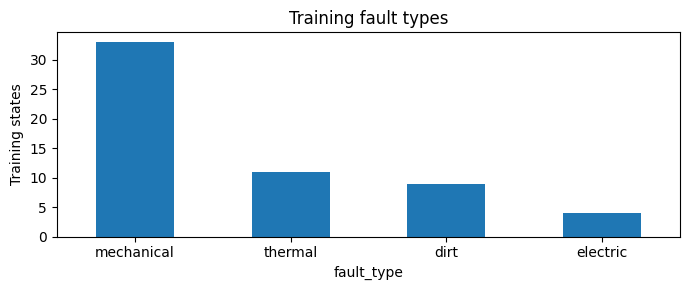

fault_type,mechanical,thermal,dirt,electric
cell_id,,,,
0.1,15,5,3,0
0.2,18,6,6,4


In [7]:
class_order = ["mechanical", "thermal", "dirt", "electric"]
class_counts = train_df["fault_type"].value_counts().reindex(class_order, fill_value=0)
display(pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(train_df) * 100).round(1),
}))
class_counts.plot.bar(figsize=(7, 3), rot=0, ylabel="Training states",
                      title="Training fault types")
plt.tight_layout()
plt.show()

display(pd.crosstab(train_df["cell_id"], train_df["fault_type"]).reindex(
    columns=class_order, fill_value=0
))

## 5. Image structure across modalities
Read training-image dimensions and decoded Pillow modes without resizing or changing files.
`500 DPI` is not an array shape. `HDR` names an acquisition modality; it does not establish
PNG bit depth. Decoded mode is reported here, not a claimed source bit depth.

This cell requires the actual images. If a file is missing or unreadable, stop and investigate;
do not silently discard its row or change the split.

In [8]:
records = []
for row in train_df.to_dict("records"):
    for modality in ["el", "bw", "hdr"]:
        path = os.path.join(CONFIG["dataset_dir"], row[f"{modality}_path"])
        with Image.open(path) as image:
            records.append({
                "sample_id": row['sample_id'],
                "modality": modality,
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
            })

image_info = pd.DataFrame(records)
display(image_info.groupby(["modality", "mode"]).size().rename("count").to_frame())
display(image_info.groupby("modality")[["width", "height"]].describe())

count
modality mode       
bw       L        48
         RGBA      9
el       L        48
         RGBA      9
hdr      RGB      48
         RGBA      9

width                                                          \
         count         mean        std     min     25%     50%     75%   
modality                                                                 
bw        57.0  2964.403509  12.261816  2943.0  2957.0  2960.0  2969.0   
el        57.0  2964.403509  12.261816  2943.0  2957.0  2960.0  2969.0   
hdr       57.0  2964.403509  12.261816  2943.0  2957.0  2960.0  2969.0   

                 height                                                 \
             max  count         mean       std     min     25%     50%   
modality                                                                 
bw        2997.0   57.0  2563.070175  13.79811  2542.0  2557.0  2559.0   
el        2997.0   57.0  2563.070175  13.79811  2542.0  2557.0  2559.0   
hdr       2997.0   57.0  2563.070175  13.79811  2542.0  2557.0  2559.0   

                          
             75%     max  
modality                  
bw        2561.0  2594.0  
el        2561.0  2594.0  
hdr       2561.0  2594.0

## 6. Paired examples: one training state per class
The labels below come from the CSV, not from visual diagnosis. Each row shows the same
state in all three modalities. These examples illustrate appearance, not class-wide rules.

For display only, images are converted to 8-bit RGB. This is **not** a chosen training
transformation and may lose information for higher-bit-depth sources. Native files remain
unchanged. Do not compare apparent brightness as a calibrated physical quantity across modalities.

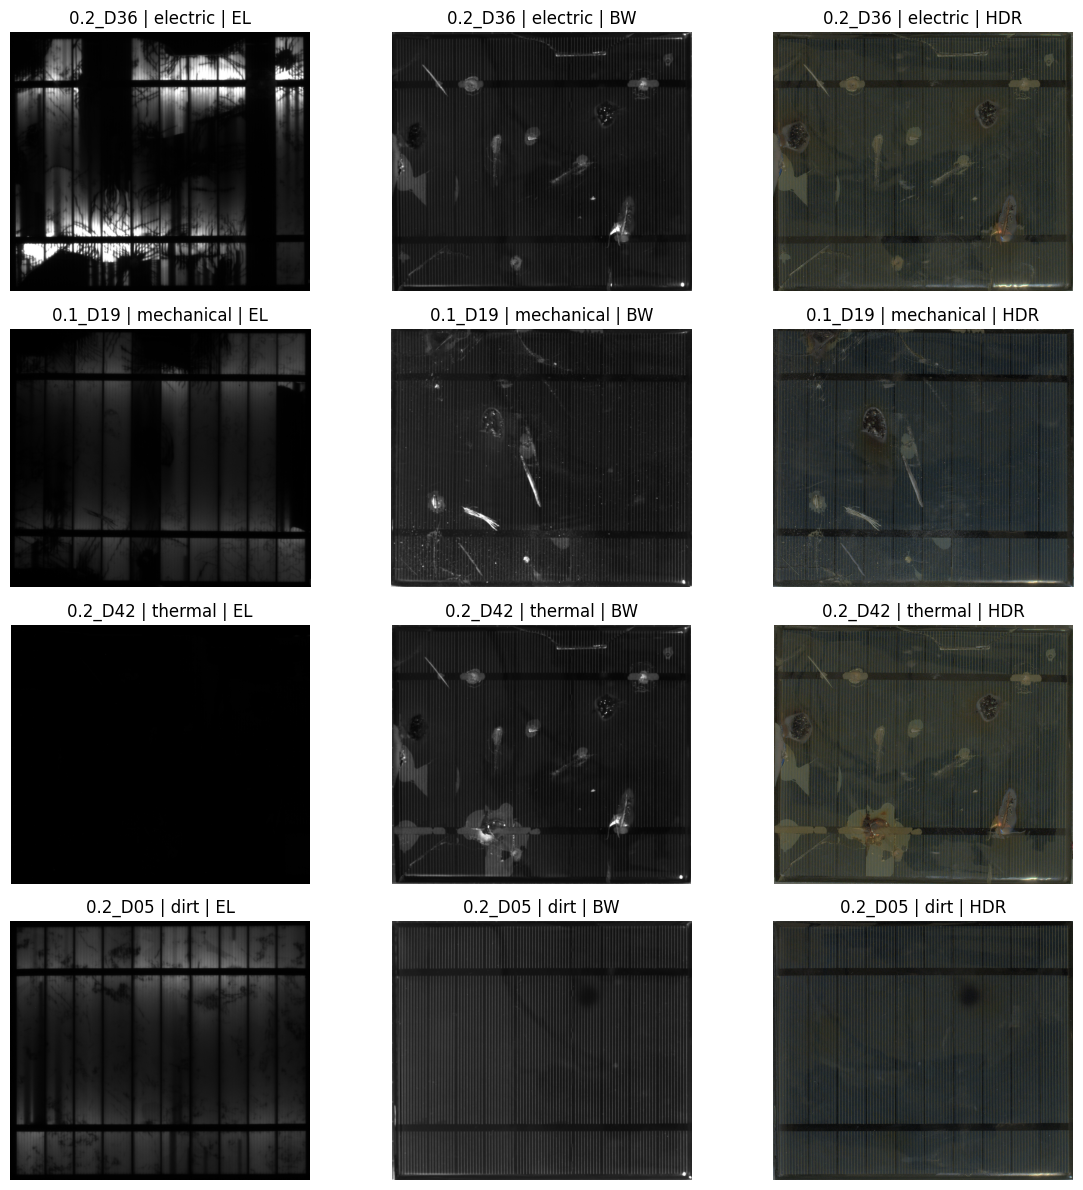

In [9]:
examples = train_df.groupby("fault_type", sort=False).head(1)
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 3 * len(examples)), squeeze=False)

for i, row in enumerate(examples.to_dict("records")):
    for j, modality in enumerate(["el", "bw", "hdr"]):
        with Image.open(os.path.join(CONFIG["dataset_dir"], row[f"{modality}_path"])) as image:
            preview = image.convert("RGB")
        axes[i, j].imshow(preview)
        axes[i, j].set_title(f"{row['sample_id']} | {row['fault_type']} | {modality.upper()}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## 7. Exploratory EL intensity summaries
To illustrate numerical EDA, compute per-image mean and standard deviation using an
**8-bit grayscale preview** of EL. These are display-derived summaries, not physical
measurements, native-range statistics or finalized model features. Conversion may discard
higher-bit-depth information; inspect the modes above before interpreting the summaries.

A dark region can be a genuine fault, not missing data. Brightness also depends on acquisition
and cell identity, so class differences do not establish a generalizable predictor.

In [10]:
records = []
for row in train_df.to_dict("records"):
    with Image.open(os.path.join(CONFIG["dataset_dir"], row["el_path"])) as image:
        preview = np.asarray(image.convert("L"), dtype=np.float32)
    records.append({
        "sample_id": row['sample_id'],
        "fault_type": row['fault_type'],
        "mean_intensity": float(preview.mean()),
        "std_intensity": float(preview.std()),
    })

el_summary = pd.DataFrame(records)
display(el_summary[["mean_intensity", "std_intensity"]].describe())

,mean_intensity,std_intensity
count,57.000000,57.000000
mean,23.611555,21.248703
std,12.553972,17.003380
min,0.543557,0.674863
25%,18.119753,15.463749
50%,21.797298,17.091105
75%,29.001680,20.018726
max,75.373039,91.902626


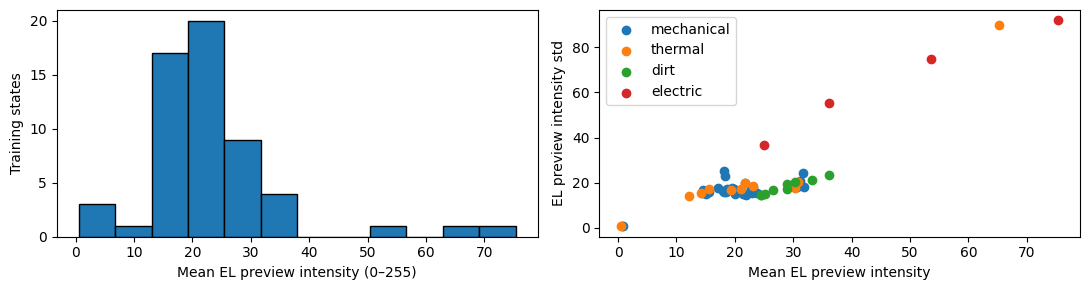

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(el_summary["mean_intensity"], bins=12, edgecolor="black")
axes[0].set(xlabel="Mean EL preview intensity (0–255)", ylabel="Training states")

for fault in class_order:
    group = el_summary.loc[el_summary["fault_type"] == fault]
    axes[1].scatter(group["mean_intensity"], group["std_intensity"], label=fault)
axes[1].set(xlabel="Mean EL preview intensity", ylabel="EL preview intensity std")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Potential outliers: investigate, do not delete
Use a box plot and the 1.5×IQR rule to identify unusual *preview means* in training.
These flags are review candidates, not corruption labels. Global thresholds can flag
rare valid faults. We do not remove rows, change labels or apply thresholds to held-out data.

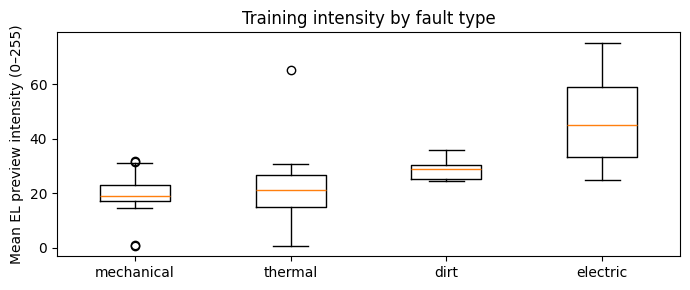

,sample_id,fault_type,mean_intensity,std_intensity
2,0.2_D42,thermal,0.543557,0.674863
20,0.1_D34,mechanical,0.720939,0.818259
31,0.2_D38,electric,53.597393,74.676826
42,0.2_D40,electric,75.373039,91.902626
46,0.2_D41,thermal,65.209122,89.744774
53,0.1_D33,mechanical,0.781641,0.855426


In [12]:
groups = [el_summary.loc[el_summary["fault_type"] == fault, "mean_intensity"]
          for fault in class_order]
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(groups)
ax.set_xticks(range(1, len(class_order) + 1), class_order)
ax.set(ylabel="Mean EL preview intensity (0–255)", title="Training intensity by fault type")
plt.tight_layout()
plt.show()

q1, q3 = el_summary["mean_intensity"].quantile([0.25, 0.75])
iqr = q3 - q1
flagged = el_summary.loc[
    (el_summary["mean_intensity"] < q1 - 1.5 * iqr)
    | (el_summary["mean_intensity"] > q3 + 1.5 * iqr)
]
display(flagged)